Analysis for question 1

In [ ]:
import pandas as pd
import matplotlib as plt
# load data gồm bảng so sánh sản phẩm đặc trưng của high value với 2 phân khúc còn lại.
df1=pd.read_csv('archive (3)/comparing_high_exclusive_pd.csv')

In [ ]:
df1.sort_values('pct_orders',ascending=False,inplace=True)



In [ ]:
plt.plot(x='')

,customer_segment,product_name,orders_with_product,total_order,pct_orders
2,High-value,Apple Honeycrisp Organic,54151,1299608,4.17
7,High-value,Organic Cucumber,49878,1299608,3.84
3,High-value,Organic Grape Tomatoes,49951,1299608,3.84
6,Medium-value,Organic Grape Tomatoes,27459,1390652,1.97
4,Medium-value,Apple Honeycrisp Organic,25483,1390652,1.83
1,Medium-value,Organic Cucumber,24940,1390652,1.79
0,low-value,Organic Grape Tomatoes,6845,524614,1.30
8,low-value,Organic Cucumber,5574,524614,1.06
5,low-value,Apple Honeycrisp Organic,5386,524614,1.03


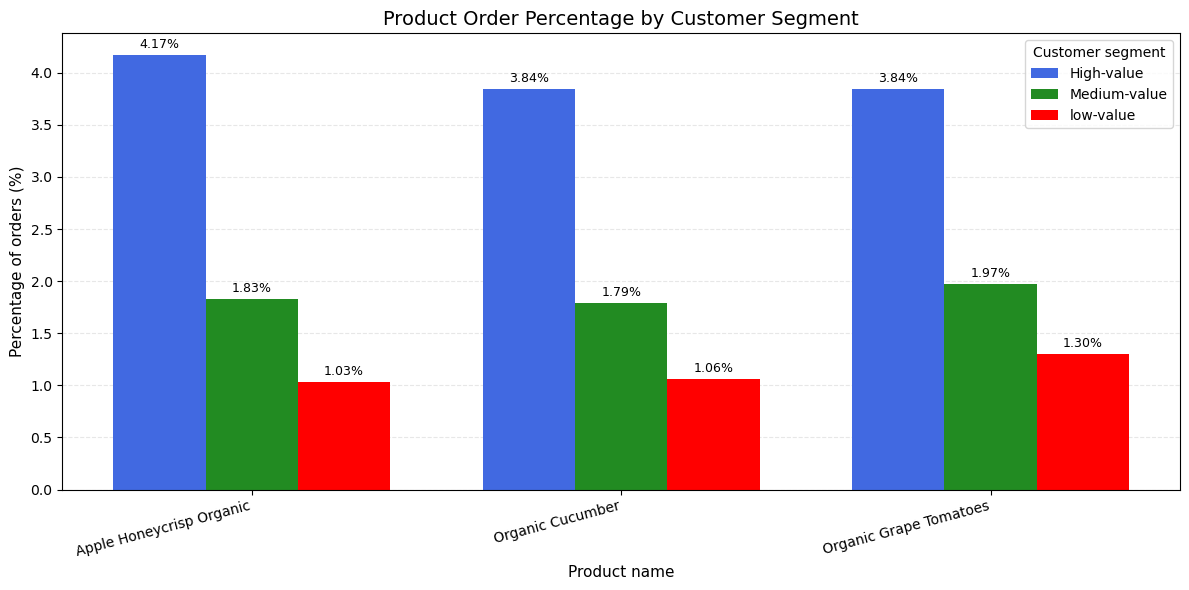

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Khai báo thứ tự sản phẩm và phân khúc
products = [
    'Apple Honeycrisp Organic',
    'Organic Cucumber',
    'Organic Grape Tomatoes'
]

segments = ['High-value', 'Medium-value', 'low-value']

# Màu sắc tương ứng với từng phân khúc
colors = {
    'High-value': 'royalblue',
    'Medium-value': 'forestgreen',
    'low-value': 'red'
}

# Tạo vị trí các cột
x = np.arange(len(products))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

# Vẽ từng nhóm cột
for i, segment in enumerate(segments):
    segment_data = (
        df1[
            df1['customer_segment'] == segment
        ]
        .set_index('product_name')
        .reindex(products)
    )

    values = segment_data['pct_orders'].to_numpy()

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=segment,
        color=colors[segment]
    )

    # Ghi phần trăm trên đầu mỗi cột
    ax.bar_label(
        bars,
        labels=[f'{v:.2f}%' if not np.isnan(v) else ''
                for v in values],
        padding=3,
        fontsize=9
    )

# Định dạng biểu đồ
ax.set_xlabel('(Product name)', fontsize=11)
ax.set_ylabel('Percentage of orders (%)', fontsize=11)
ax.set_title(
    'Product Order Percentage by Customer Segment',
    fontsize=14
)

ax.set_xticks(x)
ax.set_xticklabels(products, rotation=15, ha='right')

ax.legend(title='Customer segment')
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()
